# Name: Tushar Singh
# Rol No. 2501940055
# Course: MCA(AI &ML)
# Lab 4 — Text-to-Image Generation using Stable Diffusion



In [ ]:
!pip -q install diffusers transformers accelerate safetensors

In [ ]:
import torch, os, matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline
device="cuda" if torch.cuda.is_available() else "cpu"
print("Device:",device)
if device=="cpu":
    print("Warning: Stable Diffusion may be extremely slow or run out of RAM on CPU.")

Device: cpu


## 1. Load the pretrained pipeline

In [ ]:
MODEL_ID="runwayml/stable-diffusion-v1-5"
dtype=torch.float16 if device=="cuda" else torch.float32
pipe=StableDiffusionPipeline.from_pretrained(
    MODEL_ID, torch_dtype=dtype, safety_checker=None
)
pipe=pipe.to(device)
if device=="cuda":
    pipe.enable_attention_slicing()
print("Pipeline loaded.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Pipeline loaded.


## 2. Write a descriptive prompt

In [ ]:
prompt="A small cozy reading room with a wooden desk, warm sunlight through a window, bookshelves, detailed digital illustration"
negative_prompt="blurry, distorted, low quality, text, watermark"

## 3. Generate and display an image

  0%|          | 0/25 [00:00<?, ?it/s]

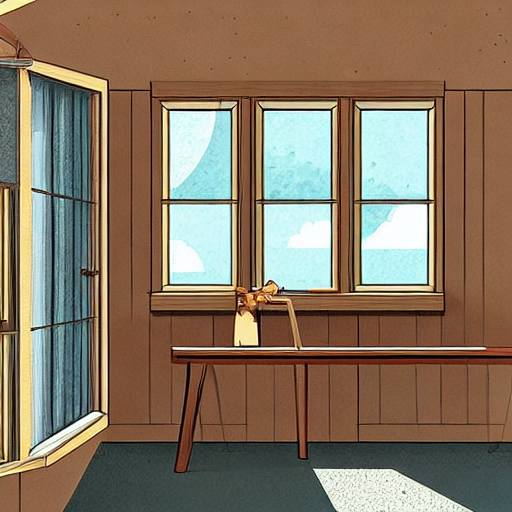

Saved lab4_outputs/generated_image.png


In [ ]:
generator=torch.Generator(device=device).manual_seed(42)
result=pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    num_inference_steps=25,
    guidance_scale=7.5,
    height=512,
    width=512,
    generator=generator
)
image=result.images[0]
os.makedirs("lab4_outputs",exist_ok=True)
image.save("lab4_outputs/generated_image.png")
display(image)
print("Saved lab4_outputs/generated_image.png")

## 4. Experiment with a second prompt

  0%|          | 0/25 [00:00<?, ?it/s]

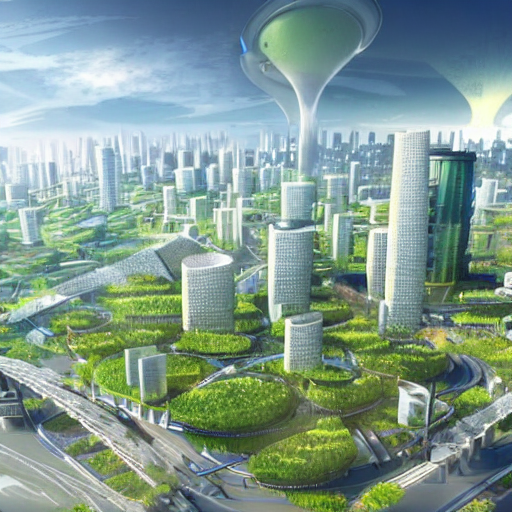

In [7]:
prompt2="A futuristic sustainable city with green rooftops, solar panels, clean public transport, bright morning, concept art"
result2=pipe(prompt2,num_inference_steps=25,guidance_scale=7.5,
             generator=torch.Generator(device=device).manual_seed(7))
image2=result2.images[0]
image2.save("lab4_outputs/second_generated_image.png")
display(image2)

## 5. Discuss the parameters

- **Prompt:** natural-language description of the desired image.
- **Negative prompt:** concepts the model should try to avoid.
- **Inference steps:** number of denoising iterations; more steps can increase time.
- **Guidance scale:** controls how strongly generation follows the prompt.
- **Seed:** makes the generation process more reproducible.

